# One night → an orbit: how a new NEO comes into focus

**Science question.** A survey reports a moving object. Before anyone follows it up, *what do the
observations actually tell us?* Is it near-Earth? How close does it come? Which numbers can we
already trust, and which are still a guess?

We replay the discovery of **2024 MK**, found by ATLAS at Sutherland (M22) on 2024 June 16. It
passed Earth at about 0.77 lunar distances thirteen days later. We fit the astrometry as it
accumulated (one night, two, three, a week, two weeks), then all of it (including later radar and
precovery observations), and watch the orbit go from *unconstrained* to *nailed down*.

What PyRoOrb provides along the way:

* `fit.is_determined` / `fit.determinacy()`: an explicit verdict on whether the data determine an
  orbit at all, with no silent nominal orbit for a single tracklet;
* `fit.range_profile()`: χ² as a function of the object's distance, the direct measurement of
  what a short arc pins down;
* `fit.element_ranges()`: non-linear (Monte-Carlo) 5–95 % intervals of the elements;
* `fit.moid_earth()`, `fit.orbit_class()`, `fit.uncertainty_parameter()` and `pyroorb.ephemeris`.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


## The observations

`fetch_observations` pulls everything the MPC has. 2024 MK also has precovery observations from
earlier years, so we take the **discovery** observation as time zero and count nights forward from
it.

In [2]:
obs = pyroorb.fetch_observations("2024 MK")
t_disc = min(o["jd_utc"] for o in obs if o.get("discovery"))
print(f"{len(obs)} optical observations, {len(obs.meta['radar'])} radar; "
      f"discovery at JD {t_disc:.3f} by station "
      f"{next(o['obscode'] for o in obs if o.get('discovery'))}")

after = np.array(sorted(o["jd_utc"] - t_disc for o in obs if o["jd_utc"] >= t_disc - 0.3))
nights, counts = np.unique(np.floor(after + 0.3).astype(int), return_counts=True)
print("observations per night after discovery (day: count):")
print(", ".join(f"{d}: {c}" for d, c in zip(nights[:16], counts[:16])))

843 optical observations, 5 radar; discovery at JD 2460478.315 by station M22
observations per night after discovery (day: count):
0: 4, 2: 9, 3: 17, 4: 9, 5: 10, 6: 19, 7: 18, 8: 9, 9: 24, 10: 42, 11: 28, 12: 201, 13: 254, 14: 43, 15: 14, 16: 42


## Fit the growing arc

`first(days)` keeps what was known `days` after discovery. The radar astrometry comes later and is
attached to `obs.meta`, so the subsets drop it; leaving it in would hand a one-night arc a
measurement it did not have.

In [3]:
def first(days):
    return obs.select(t_disc - 0.3, t_disc + days, radar=False)     # optical only

arcs = {"1 night": 0.5, "2 nights": 2.5, "3 nights": 3.5, "1 week": 7.5, "2 weeks": 14.5}
fits = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", pyroorb.UndeterminedOrbitWarning)
    for label, days in arcs.items():
        fits[label] = pyroorb.fit_orbit(first(days), designation="2024 MK")
    fits["all data"] = pyroorb.fit_orbit(obs, designation="2024 MK")

print(f"{'arc':9s} {'n':>4s}  {'determined':10s} {'a [au] (5-95 %)':>20s} {'q [au] (5-95 %)':>17s}"
      f" {'MOID [au]':>10s} {'U':>5s}  class")
for label, f in fits.items():
    if f.is_determined:
        r, moid = f.element_ranges(), f"{f.moid_earth():10.5f}"
        cls, U = f.orbit_class(), f"{f.uncertainty_parameter():5.1f}"
    else:                                  # no orbit -- only the range of orbits that fit
        r, moid, cls, U = f.determinacy()["ranges"], f"{'—':>10s}", "—", f"{'—':>5s}"
    if r is None:
        print(f"{label:9s} {f.n_observations():4d}  {'no':10s}  {f.determinacy()['headline']}")
        continue
    print(f"{label:9s} {f.n_observations():4d}  {'yes' if f.is_determined else 'no':10s} "
          f"{r['a'][0]:8.3f} – {r['a'][1]:<9.3f} {r['q'][0]:7.4f}–{r['q'][1]:<7.4f}"
          f" {moid} {U}  {cls}")

arc          n  determined      a [au] (5-95 %)   q [au] (5-95 %)  MOID [au]     U  class
1 night      4  no          Essentially unconstrained — 0.0-day, 1-opposition arc
2 nights     7  no            1.665 – 36.970     0.9956–1.0157           —     —  —
3 nights    30  yes           2.227 – 2.250      1.0091–1.0092     0.00188   8.4  Apollo (NEO)
1 week      82  yes           2.231 – 2.235      1.0092–1.0092     0.00188   7.4  Apollo (NEO)


2 weeks    509  yes           2.248 – 2.249      1.0075–1.0075     0.00175   4.5  Apollo (NEO)
all data   764  yes           2.242 – 2.242      1.0074–1.0074     0.00175   0.0  Apollo (NEO)


**Reading the table.**

* **One night** (4 observations in under an hour): PyRoOrb refuses to give an orbit. The arc is
  consistent with distances from a few lunar distances out to the edge of the scan, so not even a
  range of elements is meaningful. It still says something: digest2, PyRoOrb's built-in port,
  scores how NEO-like the motion is (next cell). That score is what puts an object on the NEOCP.
* **Two nights**: still no orbit, but now the range of orbits that fit is bounded. The semimajor
  axis could be anywhere from ~1.7 to ~37 au (and about half the solutions are not even bound),
  yet the perihelion distance *q* is already pinned near 1 au. Short arcs constrain *q* (where
  the object is and how fast it moves) long before they constrain *a* (where it goes).
* **Three nights**: the orbit is determined. *a* collapses to ±0.01 au and the Earth MOID is
  ≈ 0.0019 au (about 0.7 lunar distances): a potentially hazardous Apollo, with ten days of
  warning before the close approach.
* After that, more data shrink the uncertainty parameter *U* to 0. The last two rows move a
  little because their epoch sits at or after the 2024 Earth encounter, which changed the orbit
  (see below).

In [4]:
for label, days in (("1 night", 0.5), ("2 nights", 2.5)):
    d2 = pyroorb.digest2_scores(first(days))          # digest2 needs no orbit fit
    shown = {d2["classes"][c]: round(s) for c, s in d2["raw"].items() if c != "Int" and s >= 1}
    print(f"digest2 scores (0-100) after {label}:", shown)

digest2 scores (0-100) after 1 night: {'NEO(q < 1.3)': 90, 'NEO(H <= 22)': 86, 'NEO(H <= 18)': 5, 'Mars Crosser': 7, 'Hungaria gr.': 1, 'Pallas group': 1}


digest2 scores (0-100) after 2 nights: {'NEO(q < 1.3)': 61, 'NEO(H <= 22)': 53, 'NEO(H <= 18)': 5, 'Mars Crosser': 16, 'Hungaria gr.': 4, 'Phocaea group': 22, 'Pallas group': 2, 'Jupiter Comet': 1}


## What one, two and three nights say about the distance

The **range profile** fixes the object's distance at the first observation, refits the other five
degrees of freedom, and records χ². A flat valley means the data cannot tell near from far; a
sharp minimum means the distance (and with it the orbit) is pinned. The dotted line is the true
distance at discovery, from the final orbit.

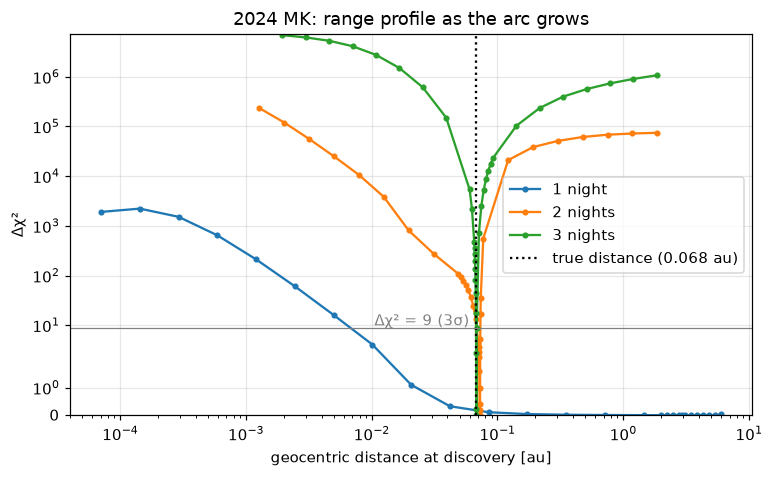

In [5]:
truth = pyroorb.ephemeris(fits["all data"], t_disc, t_disc, site="500", full=False)[0]["delta_au"]

fig, ax = plt.subplots()
for label in ("1 night", "2 nights", "3 nights"):
    rows = fits[label].range_profile()["rows"]
    rho = np.array([r["rho"] for r in rows]); chi2 = np.array([r["chi2"] for r in rows])
    ax.plot(rho, chi2 - chi2.min(), marker=".", label=label)
ax.axvline(truth, ls=":", c="k", label=f"true distance ({truth:.3f} au)")
ax.axhline(9, c="grey", lw=0.8)
ax.text(0.0105, 10, "Δχ² = 9 (3σ)", color="grey")
ax.set(xscale="log", yscale="symlog", xlabel="geocentric distance at discovery [au]",
       ylabel="Δχ²", title="2024 MK: range profile as the arc grows", ylim=(0, None))
ax.legend()
plt.show()

## How close will it come?

The practical question for a fresh NEO is the close approach. We ask each determined fit for the
geocentric ephemeris around 2024 June 29 and compare with JPL's published close approach (from the
SBDB close-approach API).

In [6]:
import json, urllib.parse, urllib.request

def closest(fit, start="2024-06-28", stop="2024-06-30", step=1 / 1440):
    rows = pyroorb.ephemeris(fit, start, stop, step=step, site="500", full=False)
    best = min(rows, key=lambda r: r["delta_au"])
    return best["date_iso"], best["delta_au"]

LD = 0.00256955529   # lunar distance in au
for label, f in fits.items():
    if f.is_determined:
        t, d = closest(f)
        print(f"{label:9s} closest approach {t} UTC at {d:.6f} au = {d / LD:.3f} LD")

url = ("https://ssd-api.jpl.nasa.gov/cad.api?des=2024%20MK&date-min=2024-06-20"
       "&date-max=2024-07-10&dist-max=0.05")
try:
    jpl = json.load(urllib.request.urlopen(url, timeout=30))
    f_ = dict(zip(jpl["fields"], jpl["data"][0]))
    print(f"JPL       closest approach {f_['cd']} TDB at {float(f_['dist']):.6f} au "
          f"= {float(f_['dist']) / LD:.3f} LD")
except Exception as ex:
    print("JPL close-approach API unavailable:", ex)

3 nights  closest approach 2024-06-29 13:30:59 UTC at 0.001974 au = 0.768 LD


1 week    closest approach 2024-06-29 13:48:59 UTC at 0.001975 au = 0.769 LD


2 weeks   closest approach 2024-06-29 13:47:59 UTC at 0.001975 au = 0.769 LD


all data  closest approach 2024-06-29 13:47:59 UTC at 0.001975 au = 0.769 LD


JPL       closest approach 2024-Jun-29 13:49 TDB at 0.001975 au = 0.769 LD


The three-night orbit already predicts the close-approach distance to within a few hundred km of
JPL's value, with the time off by about 20 minutes. From one week on, the prediction matches JPL
to the minute.

## Final orbit vs JPL

The full fit uses all the optical astrometry plus the radar delay/Doppler measurements.

In [7]:
f = fits["all data"]
# JPL Horizons: osculating heliocentric ecliptic elements of JPL's orbit at OUR epoch.
q = urllib.parse.urlencode({"format": "json", "COMMAND": "'DES=2024 MK;'",
                            "EPHEM_TYPE": "ELEMENTS", "CENTER": "'500@10'",
                            "REF_PLANE": "ECLIPTIC", "TLIST": f"'{f.epoch_jd()}'",
                            "TIME_TYPE": "TDB", "OUT_UNITS": "AU-D", "CSV_FORMAT": "YES"})
try:
    res = json.load(urllib.request.urlopen("https://ssd.jpl.nasa.gov/api/horizons.api?" + q,
                                           timeout=60))["result"]
    row = res.split("$$SOE")[1].split("$$EOE")[0].split(",")
    # CSV columns: JDTDB, date, EC, QR, IN, OM, W, Tp, N, MA, TA, A, AD, PR
    jpl = {"e": float(row[2]), "q": float(row[3]), "i": float(row[4]), "a": float(row[11])}
    print(f"osculating elements at {f.epoch_iso()[:19]} TDB:")
    for k in ("a", "e", "q", "i"):
        v, s = f.elements()[k], f.element_sigmas()[k]
        print(f"  {k}: PyRoOrb {v:.8f} ± {s:.1e}   JPL Horizons {jpl[k]:.8f}"
              f"   difference {abs(v - jpl[k]) / s:.1f} sigma")
except Exception as ex:
    print("Horizons API unavailable:", ex)
print(f"rms {f.rms_residual():.2f}\", {f.n_observations()} obs used, "
      f"{f.n_oppositions()} oppositions, U = {f.uncertainty_parameter():.0f}, class {f.orbit_class()}")

osculating elements at 2024-06-29 22:28:02 TDB:
  a: PyRoOrb 2.24219675 ± 2.0e-08   JPL Horizons 2.24219677   difference 0.9 sigma
  e: PyRoOrb 0.55070608 ± 4.1e-09   JPL Horizons 0.55070608   difference 0.2 sigma
  q: PyRoOrb 1.00740537 ± 4.4e-09   JPL Horizons 1.00740538   difference 2.2 sigma
  i: PyRoOrb 8.48654789 ± 1.0e-06   JPL Horizons 8.48655145   difference 3.5 sigma
rms 0.77", 764 obs used, 2 oppositions, U = 0, class Apollo (NEO)


PyRoOrb places its epoch inside the arc, here on the day of the Earth encounter, so we ask
Horizons for JPL's orbit at that same instant. The osculating elements at an encounter
epoch are unusually sensitive (Earth's pull dominates at that moment), which makes this a demanding
comparison. JPL's published elements and MOID are at a 2026 epoch, after the encounter reshaped the
orbit, so they are not comparable directly.

The two independent solutions agree to about one part in 10⁸ in *a*, *e* and *q*. The residual
differences of 1–3.5 formal σ are about the size you would expect from different observation
weighting, outlier rejection and force models. (This fit is planets-only; JPL also includes the
16 largest asteroids.)

### Caveats

* A subset of a later dataset is not exactly what observers had on those nights: some astrometry
  was remeasured, and the precise timing of reports is lost. The progression is representative,
  not a reconstruction of the NEOCP page.
* The one-night verdict ("no orbit") is deliberate. A nominal orbit from a single tracklet can be
  confidently wrong. PyRoOrb shows the range of solutions instead, and `fit.elements()` on such a
  fit is a nominal solution only (hence the `UndeterminedOrbitWarning`).